<a href="https://colab.research.google.com/github/Abdullah-567/Deep-Learning-Tutorials/blob/main/Tutorial5_CNN_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 5: Convolutional Neural Network (CNN) — PyTorch Implementation
CIFAR-10 image classification, a PyTorch port of the TensorFlow/Keras tutorial,

**Sections**
1. Import libraries
2. Load & preprocess CIFAR-10
3. Visualize data
4. Build the CNN
5. Loss & optimizer (the "compile" step)
6. Train
7. Evaluate
8. Plot accuracy/loss
9. Predictions
10. Visualize predictions
11. **Task 1** – architecture experiments
12. **Task 2 & 3** – improve accuracy, fix over/underfitting
13. **Additional Notes** – forward/backprop maths, verified with autograd

> Runs on CPU, but a GPU (Colab: Runtime → Change runtime type → GPU) is much faster.

## Step 1 — Import Libraries

In [ ]:
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as T

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.11.0+cu130 | device: cuda


## Step 2 — Load and Preprocess CIFAR-10
`ToTensor()` converts images to `[C, H, W]` float tensors and scales pixels from `[0, 255]` to `[0, 1]` (same as `/ 255.0` in the Keras version).

In [ ]:
BATCH_SIZE = 64
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

base_tf = T.ToTensor()   # [0,255] -> [0,1]
train_set = torchvision.datasets.CIFAR10(root="./data", train=True,  download=True, transform=base_tf)
test_set  = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=base_tf)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_set,  batch_size=256,        shuffle=False, num_workers=2)

print("Train:", len(train_set), "| Test:", len(test_set))
print("Image tensor shape:", train_set[0][0].shape, "| pixel range:",
      float(train_set[0][0].min()), "-", float(train_set[0][0].max()))

100%|██████████| 170M/170M [28:18<00:00, 100kB/s]


Train: 50000 | Test: 10000
Image tensor shape: torch.Size([3, 32, 32]) | pixel range: 0.0 - 1.0


## Step 3 — Visualize Some Data

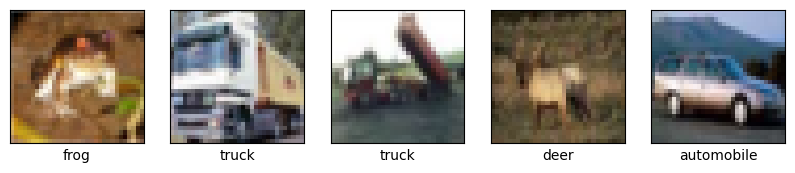

In [ ]:
plt.figure(figsize=(10, 3))
for i in range(5):
    img, label = train_set[i]
    plt.subplot(1, 5, i + 1)
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.imshow(img.permute(1, 2, 0))          # CHW -> HWC for matplotlib
    plt.xlabel(class_names[label])
plt.show()

## Step 4 — Build the CNN
Same architecture as the tutorial: Conv(32) → MaxPool → Conv(64) → MaxPool → Conv(64) → Flatten → Dense(64) → Dense(10).

Note: Keras uses a `softmax` output layer. In PyTorch, `nn.CrossEntropyLoss` applies log-softmax internally, so the model outputs **raw logits** (softmax is applied only when we need probabilities).

In [ ]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3),  nn.ReLU(),   # 32x32 -> 30x30
            nn.MaxPool2d(2),                                # -> 15x15
            nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(),   # -> 13x13
            nn.MaxPool2d(2),                                # -> 6x6
            nn.Conv2d(64, 64, kernel_size=3), nn.ReLU(),   # -> 4x4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                 # 64*4*4 = 1024
            nn.Linear(64 * 4 * 4, 64), nn.ReLU(),
            nn.Linear(64, 10),            # logits (softmax folded into the loss)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = BaselineCNN().to(device)

## Step 5 — Loss, Optimizer and Model Summary (the "compile" step)

In [ ]:
criterion = nn.CrossEntropyLoss()                       # = sparse_categorical_crossentropy (+ softmax)
optimizer = torch.optim.Adam(model.parameters())        # Adam, default lr=1e-3 (same as Keras)

def model_summary(model, input_size=(1, 3, 32, 32)):
    """Keras-style summary: output shape per layer + parameter counts."""
    rows, hooks = [], []
    def hook(name):
        def fn(m, inp, out):
            n = sum(p.numel() for p in m.parameters(recurse=False))
            rows.append((name, tuple(out.shape), n))
        return fn
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(hook(f"{name} ({m.__class__.__name__})")))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_size, device=next(model.parameters()).device))
    model.train(was_training)
    for h in hooks: h.remove()
    print(f"{'Layer':<34}{'Output shape':<22}{'Params':>10}")
    print("-" * 66)
    for r in rows:
        print(f"{r[0]:<34}{str(r[1]):<22}{r[2]:>10,}")
    total = sum(p.numel() for p in model.parameters())
    print("-" * 66)
    print(f"Total params: {total:,}")

model_summary(model)

Layer                             Output shape              Params
------------------------------------------------------------------
features.0 (Conv2d)               (1, 32, 30, 30)              896
features.1 (ReLU)                 (1, 32, 30, 30)                0
features.2 (MaxPool2d)            (1, 32, 15, 15)                0
features.3 (Conv2d)               (1, 64, 13, 13)           18,496
features.4 (ReLU)                 (1, 64, 13, 13)                0
features.5 (MaxPool2d)            (1, 64, 6, 6)                  0
features.6 (Conv2d)               (1, 64, 4, 4)             36,928
features.7 (ReLU)                 (1, 64, 4, 4)                  0
classifier.0 (Flatten)            (1, 1024)                      0
classifier.1 (Linear)             (1, 64)                   65,600
classifier.2 (ReLU)               (1, 64)                        0
classifier.3 (Linear)             (1, 10)                      650
--------------------------------------------------------------

## Step 6 — Train the Model
Reusable helpers: one epoch of training, evaluation, and a `fit()` that records a Keras-like `history` dict (validation uses the test set, as in the tutorial).

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None, scheduler=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
                if scheduler is not None:       # per-batch schedulers (OneCycleLR)
                    scheduler.step()
            total_loss += loss.item() * x.size(0)
            correct    += (logits.argmax(1) == y).sum().item()
            n          += x.size(0)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, criterion, optimizer, epochs=10, scheduler=None, verbose=True):
    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scheduler)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[k].append(v)
        if verbose:
            print(f"Epoch {ep:>2}/{epochs} - {time.time()-t0:5.1f}s - "
                  f"loss: {tr_loss:.4f} - accuracy: {tr_acc:.4f} - "
                  f"val_loss: {va_loss:.4f} - val_accuracy: {va_acc:.4f}")
    return history

history = fit(model, train_loader, test_loader, criterion, optimizer, epochs=10)

Epoch  1/10 -  11.8s - loss: 1.6907 - accuracy: 0.3690 - val_loss: 1.4252 - val_accuracy: 0.4812
Epoch  2/10 -  10.9s - loss: 1.3508 - accuracy: 0.5109 - val_loss: 1.2512 - val_accuracy: 0.5512
Epoch  3/10 -  11.0s - loss: 1.2044 - accuracy: 0.5684 - val_loss: 1.1910 - val_accuracy: 0.5699
Epoch  4/10 -  10.9s - loss: 1.1065 - accuracy: 0.6071 - val_loss: 1.1323 - val_accuracy: 0.5909
Epoch  5/10 -  10.1s - loss: 1.0305 - accuracy: 0.6363 - val_loss: 1.0161 - val_accuracy: 0.6409
Epoch  6/10 -  10.9s - loss: 0.9607 - accuracy: 0.6619 - val_loss: 1.0062 - val_accuracy: 0.6442
Epoch  7/10 -  11.2s - loss: 0.9039 - accuracy: 0.6807 - val_loss: 1.0236 - val_accuracy: 0.6412
Epoch  8/10 -  11.0s - loss: 0.8632 - accuracy: 0.6975 - val_loss: 0.8985 - val_accuracy: 0.6802
Epoch  9/10 -  11.0s - loss: 0.8263 - accuracy: 0.7099 - val_loss: 0.9008 - val_accuracy: 0.6862
Epoch 10/10 -  11.2s - loss: 0.7923 - accuracy: 0.7216 - val_loss: 0.9035 - val_accuracy: 0.6848


## Step 7 — Evaluate the Model

In [ ]:
test_loss, test_acc = run_epoch(model, test_loader, criterion)
print(f"Test accuracy: {test_acc:.4f}   (test loss: {test_loss:.4f})")

Test accuracy: 0.6848   (test loss: 0.9035)


## Step 8 — Plot Training and Validation Accuracy/Loss

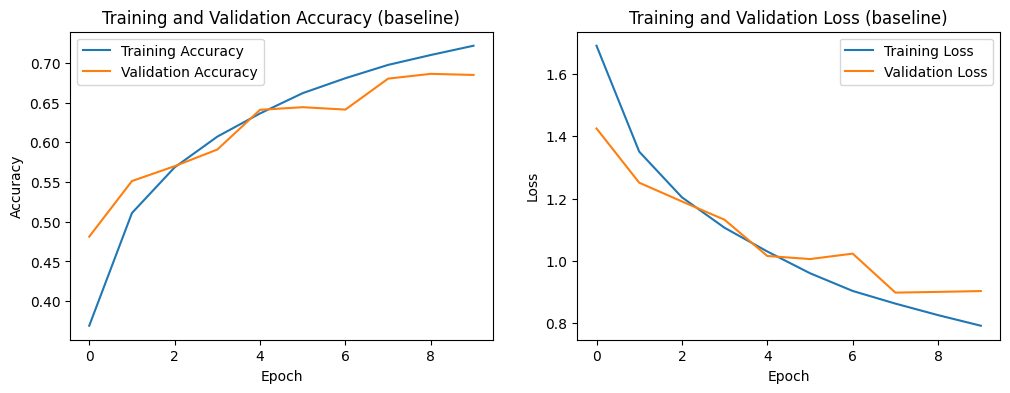

In [ ]:
def plot_history(history, title=""):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history["accuracy"], label="Training Accuracy")
    plt.plot(history["val_accuracy"], label="Validation Accuracy")
    plt.title(f"Training and Validation Accuracy {title}")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history["loss"], label="Training Loss")
    plt.plot(history["val_loss"], label="Validation Loss")
    plt.title(f"Training and Validation Loss {title}")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
    plt.show()

plot_history(history, "(baseline)")

**Purpose of plots**
- Training accuracy keeps improving while validation accuracy plateaus or drops → **overfitting**.
- Both curves low / a persistent large gap with poor scores overall → **underfitting** or poor generalization.

## Step 9 — Make Predictions on Test Data

In [ ]:
model.eval()
with torch.no_grad():
    x5 = torch.stack([test_set[i][0] for i in range(5)]).to(device)
    predictions = F.softmax(model(x5), dim=1).cpu().numpy()   # class probabilities, shape (5, 10)
print(predictions.round(3))

[[0.005 0.001 0.013 0.716 0.    0.252 0.001 0.    0.012 0.   ]
 [0.002 0.018 0.    0.    0.    0.    0.    0.    0.979 0.001]
 [0.059 0.144 0.009 0.017 0.002 0.003 0.003 0.003 0.7   0.059]
 [0.68  0.136 0.005 0.001 0.004 0.    0.001 0.    0.163 0.009]
 [0.    0.    0.033 0.119 0.627 0.061 0.153 0.002 0.003 0.   ]]


## Step 10 — Visualize Predictions

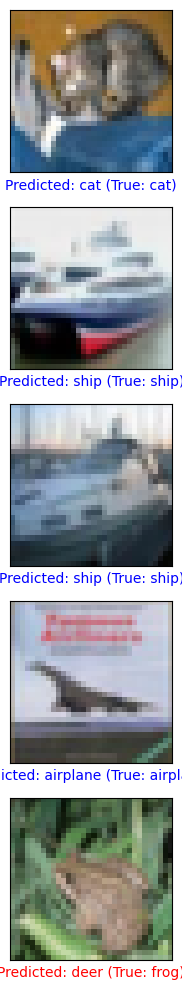

In [ ]:
test_labels = np.array(test_set.targets)

def plot_image(i, predictions_array, true_label, img, class_names):
    predictions_array, true_label, img = predictions_array[i], true_label[i], img[i]
    plt.grid(False); plt.xticks([]); plt.yticks([])
    plt.imshow(img.permute(1, 2, 0))
    predicted_label = int(np.argmax(predictions_array))
    color = "blue" if predicted_label == true_label else "red"
    plt.xlabel(f"Predicted: {class_names[predicted_label]} (True: {class_names[true_label]})", color=color)

test_images = [test_set[i][0] for i in range(5)]
plt.figure(figsize=(5, 10))
for i in range(5):
    plt.subplot(5, 1, i + 1)
    plot_image(i, predictions, test_labels, test_images, class_names)
plt.tight_layout()
plt.show()

---
# Task 1 — Experiment with Different Architectures
A configurable CNN builder lets us vary: **filter (kernel) size**, **number of conv layers / filters**, and **number/size of fully connected layers**. `'M'` in the config means a 2×2 max-pool.

In [ ]:
class ConfigurableCNN(nn.Module):
    def __init__(self, conv_cfg, fc_units, kernel_size=3, padding=0,
                 batch_norm=False, conv_dropout=0.0, fc_dropout=0.0, num_classes=10):
        super().__init__()
        layers, in_ch = [], 3
        for v in conv_cfg:
            if v == 'M':
                layers.append(nn.MaxPool2d(2))
                if conv_dropout > 0: layers.append(nn.Dropout2d(conv_dropout))
            else:
                layers.append(nn.Conv2d(in_ch, v, kernel_size, padding=padding, bias=not batch_norm))
                if batch_norm: layers.append(nn.BatchNorm2d(v))
                layers.append(nn.ReLU(inplace=True))
                in_ch = v
        self.features = nn.Sequential(*layers)

        with torch.no_grad():                                   # infer flattened size
            flat = self.features(torch.zeros(1, 3, 32, 32)).numel()

        head, prev = [nn.Flatten()], flat
        for u in fc_units:
            head += [nn.Linear(prev, u), nn.ReLU(inplace=True)]
            if fc_dropout > 0: head.append(nn.Dropout(fc_dropout))
            prev = u
        head.append(nn.Linear(prev, num_classes))
        self.classifier = nn.Sequential(*head)

    def forward(self, x):
        return self.classifier(self.features(x))


experiments = {
    "Baseline (k=3)":            dict(conv_cfg=[32, 'M', 64, 'M', 64],                     fc_units=[64],           kernel_size=3),
    "Kernel 5x5":                dict(conv_cfg=[32, 'M', 64, 'M', 64],                     fc_units=[64],           kernel_size=5),
    "Kernel 2x2":                dict(conv_cfg=[32, 'M', 64, 'M', 64],                     fc_units=[64],           kernel_size=2),
    "More filters":              dict(conv_cfg=[64, 'M', 128, 'M', 128],                   fc_units=[64],           kernel_size=3),
    "More conv layers":          dict(conv_cfg=[32, 32, 'M', 64, 64, 'M', 128, 128],       fc_units=[64],           kernel_size=3, padding=1),
    "More FC layers/neurons":    dict(conv_cfg=[32, 'M', 64, 'M', 64],                     fc_units=[256, 128, 64], kernel_size=3),
    "Deeper + wider (all)":      dict(conv_cfg=[64, 64, 'M', 128, 128, 'M', 256],          fc_units=[256, 128],     kernel_size=3, padding=1),
}

EXP_EPOCHS = 10
results, histories = {}, {}
for name, cfg in experiments.items():
    print(f"\n=== {name} ===")
    torch.manual_seed(SEED)
    m = ConfigurableCNN(**cfg).to(device)
    n_params = sum(p.numel() for p in m.parameters())
    opt = torch.optim.Adam(m.parameters())
    h = fit(m, train_loader, test_loader, nn.CrossEntropyLoss(), opt, epochs=EXP_EPOCHS, verbose=False)
    histories[name] = h
    results[name] = {
        "params": n_params,
        "train_acc": h["accuracy"][-1],
        "val_acc": h["val_accuracy"][-1],
        "best_val_acc": max(h["val_accuracy"]),
        "gap (train-val)": h["accuracy"][-1] - h["val_accuracy"][-1],
        "val_loss": h["val_loss"][-1],
    }
    print(f"params={n_params:,} | train_acc={h['accuracy'][-1]:.4f} | val_acc={h['val_accuracy'][-1]:.4f}")


=== Baseline (k=3) ===
params=122,570 | train_acc=0.7140 | val_acc=0.6818

=== Kernel 5x5 ===
params=160,970 | train_acc=0.7219 | val_acc=0.6675

=== Kernel 2x2 ===
params=173,290 | train_acc=0.7225 | val_acc=0.6909

=== More filters ===
params=355,018 | train_acc=0.7910 | val_acc=0.7239

=== More conv layers ===
params=812,010 | train_acc=0.8672 | val_acc=0.7375

=== More FC layers/neurons ===
params=360,522 | train_acc=0.7591 | val_acc=0.6925

=== Deeper + wider (all) ===
params=4,784,074 | train_acc=0.9616 | val_acc=0.7481


### Compare the modified models with the original

,params,train_acc,val_acc,best_val_acc,gap (train-val),val_loss
Deeper + wider (all),4784074,0.9616,0.7481,0.7531,0.2135,1.2383
More conv layers,812010,0.8672,0.7375,0.7524,0.1297,0.8511
More filters,355018,0.7910,0.7239,0.7239,0.0671,0.8371
More FC layers/neurons,360522,0.7591,0.6925,0.6937,0.0666,0.8998
Kernel 2x2,173290,0.7225,0.6909,0.6909,0.0316,0.8898
Baseline (k=3),122570,0.7140,0.6818,0.6833,0.0322,0.9189
Kernel 5x5,160970,0.7219,0.6675,0.6776,0.0544,0.9605


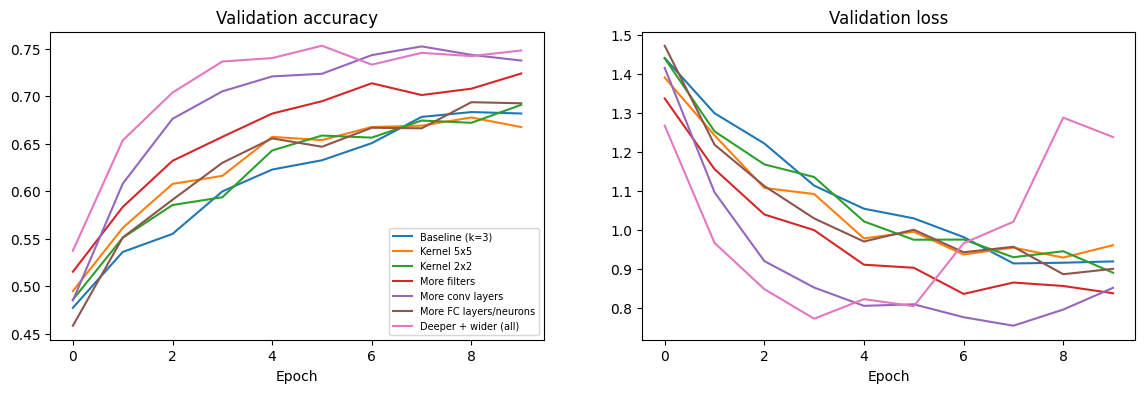

In [ ]:
df = pd.DataFrame(results).T
df["params"] = df["params"].astype(int)
display(df.round(4).sort_values("val_acc", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, h in histories.items():
    ax[0].plot(h["val_accuracy"], label=name)
    ax[1].plot(h["val_loss"], label=name)
ax[0].set_title("Validation accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend(fontsize=7)
ax[1].set_title("Validation loss");     ax[1].set_xlabel("Epoch")
plt.show()

**How to read the results:** a larger *gap (train − val)* means more overfitting. Deeper/wider models usually raise accuracy but overfit faster without regularization — which is exactly what Tasks 2 and 3 address.

---
# Task 2 & 3 — Improve Accuracy and Remove Over/Underfitting
Techniques used (each targets a specific problem):

| Technique | Fixes |
|---|---|
| Data augmentation (random crop + horizontal flip) | overfitting (more varied data) |
| Batch Normalization | faster/stabler training, mild regularization |
| Dropout (conv + FC) | overfitting |
| Weight decay (AdamW) | overfitting |
| More capacity (deeper/wider net) | underfitting |
| OneCycle LR schedule + more epochs | better convergence |
| Mean/std normalization | better optimization |

In [ ]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.ToTensor(), T.Normalize(MEAN, STD)])
test_tf  = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

train_set_aug = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=train_tf)
test_set_norm = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=test_tf)

train_loader_aug = DataLoader(train_set_aug, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
test_loader_norm = DataLoader(test_set_norm, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

improved_cfg = dict(
    conv_cfg=[64, 64, 'M', 128, 128, 'M', 256, 256, 'M'],
    fc_units=[256], kernel_size=3, padding=1,
    batch_norm=True, conv_dropout=0.1, fc_dropout=0.5,
)

IMPROVED_EPOCHS = 30            # lower to ~15 on CPU if it is too slow
torch.manual_seed(SEED)
improved = ConfigurableCNN(**improved_cfg).to(device)
model_summary(improved)

opt = torch.optim.AdamW(improved.parameters(), lr=1e-3, weight_decay=5e-4)
steps_per_epoch = len(train_loader_aug)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, epochs=IMPROVED_EPOCHS, steps_per_epoch=steps_per_epoch)

hist_imp = fit(improved, train_loader_aug, test_loader_norm, nn.CrossEntropyLoss(), opt,
               epochs=IMPROVED_EPOCHS, scheduler=sched)

Layer                             Output shape              Params
------------------------------------------------------------------
features.0 (Conv2d)               (1, 64, 32, 32)            1,728
features.1 (BatchNorm2d)          (1, 64, 32, 32)              128
features.2 (ReLU)                 (1, 64, 32, 32)                0
features.3 (Conv2d)               (1, 64, 32, 32)           36,864
features.4 (BatchNorm2d)          (1, 64, 32, 32)              128
features.5 (ReLU)                 (1, 64, 32, 32)                0
features.6 (MaxPool2d)            (1, 64, 16, 16)                0
features.7 (Dropout2d)            (1, 64, 16, 16)                0
features.8 (Conv2d)               (1, 128, 16, 16)          73,728
features.9 (BatchNorm2d)          (1, 128, 16, 16)             256
features.10 (ReLU)                (1, 128, 16, 16)               0
features.11 (Conv2d)              (1, 128, 16, 16)         147,456
features.12 (BatchNorm2d)         (1, 128, 16, 16)            

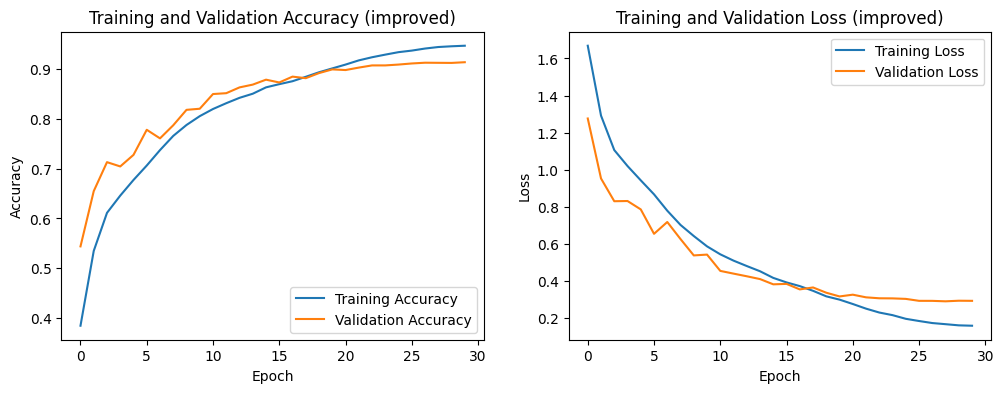

Improved model test accuracy: 0.9133
Baseline model test accuracy: 0.6848


In [ ]:
plot_history(hist_imp, "(improved)")

imp_loss, imp_acc = run_epoch(improved, test_loader_norm, nn.CrossEntropyLoss())
print(f"Improved model test accuracy: {imp_acc:.4f}")
print(f"Baseline model test accuracy: {test_acc:.4f}")

### Diagnose over/underfitting: baseline vs improved

Baseline   train=0.722  val=0.685  gap=+0.037  ->  GOOD FIT (small gap, high accuracy)
Improved   train=0.946  val=0.913  gap=+0.033  ->  GOOD FIT (small gap, high accuracy)


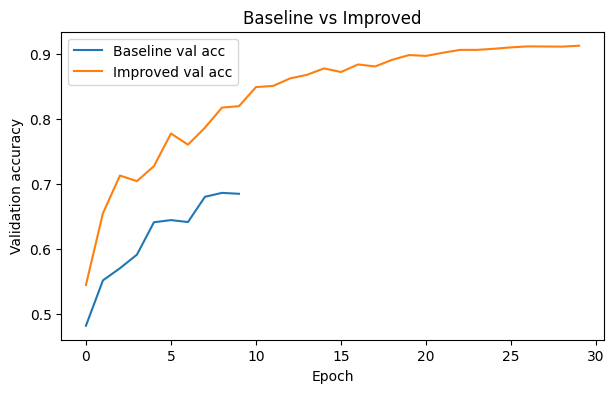

In [ ]:
def diagnose(name, h):
    tr, va = h["accuracy"][-1], h["val_accuracy"][-1]
    gap = tr - va
    if tr < 0.70:                 verdict = "UNDERFITTING (low training accuracy -> add capacity / train longer)"
    elif gap > 0.10:              verdict = "OVERFITTING (large train-val gap -> regularize / augment)"
    else:                         verdict = "GOOD FIT (small gap, high accuracy)"
    print(f"{name:<10} train={tr:.3f}  val={va:.3f}  gap={gap:+.3f}  ->  {verdict}")

diagnose("Baseline", history)
diagnose("Improved", hist_imp)

plt.figure(figsize=(7, 4))
plt.plot(history["val_accuracy"], label="Baseline val acc")
plt.plot(hist_imp["val_accuracy"], label="Improved val acc")
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy"); plt.legend(); plt.title("Baseline vs Improved")
plt.show()

### Predictions from the improved model

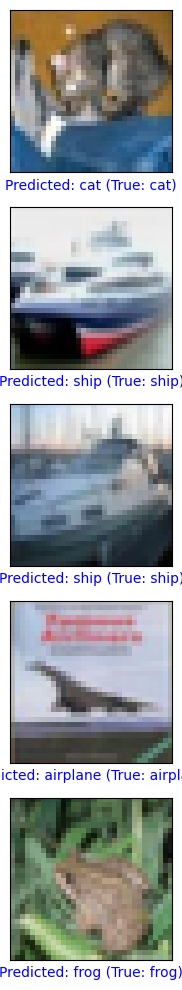

In [ ]:
improved.eval()
with torch.no_grad():
    xb = torch.stack([test_set_norm[i][0] for i in range(5)]).to(device)
    preds_imp = F.softmax(improved(xb), dim=1).cpu().numpy()

plt.figure(figsize=(5, 10))
for i in range(5):
    plt.subplot(5, 1, i + 1)
    plot_image(i, preds_imp, test_labels, test_images, class_names)   # show un-normalized images
plt.tight_layout(); plt.show()

---
# Additional Notes — Forward & Backpropagation by Hand (verified with PyTorch autograd)
The tutorial's worked example: a 4×4 grayscale image, two 3×3 filters (stride 1, no padding) → ReLU → 2×2 max-pool → fully connected layer (2 neurons, ReLU) → MSE loss with targets `[2.0, 1.0]`, learning rate 0.01.

Below, PyTorch computes the same pipeline exactly, so you can check each hand-computed number.

In [ ]:
torch.set_printoptions(precision=4, sci_mode=False)

img = torch.tensor([[1, 2, 0, 1],
                    [0, 1, 2, 1],
                    [1, 0, 1, 0],
                    [2, 1, 0, 1]], dtype=torch.float32).view(1, 1, 4, 4)

f1 = torch.tensor([[ 1, 0, -1],
                   [ 0, 1,  0],
                   [-1, 0,  1]], dtype=torch.float32)
f2 = torch.tensor([[0,  1, 0],
                   [1, -1, 1],
                   [0,  1, 0]], dtype=torch.float32)

W_conv = torch.stack([f1, f2]).unsqueeze(1).clone().requires_grad_(True)     # (2 filters, 1 ch, 3, 3)

# ---- 1.2 Convolution (PyTorch conv2d is cross-correlation = the sliding-window sum used in the notes)
conv = F.conv2d(img, W_conv)                       # (1, 2, 2, 2)
conv.retain_grad()
print("Conv output 1:\n", conv[0, 0].detach())
print("Conv output 2:\n", conv[0, 1].detach())

# ---- 1.3 ReLU
relu = F.relu(conv)
print("\nReLU output 1:\n", relu[0, 0].detach())
print("ReLU output 2:\n", relu[0, 1].detach())

# ---- 1.4 Max-pool 2x2, stride 2
pooled = F.max_pool2d(relu, 2)                     # (1, 2, 1, 1)
pooled.retain_grad()
print("\nPooled output 1:", pooled[0, 0].item(), "| Pooled output 2:", pooled[0, 1].item())

# ---- 1.5 Fully connected layer (weights/biases from the notes)
flat = pooled.flatten(1)                           # (1, 2)
W_fc = torch.tensor([[0.1, 0.2], [0.3, -0.2]], requires_grad=True)
b_fc = torch.tensor([0.5, -0.5], requires_grad=True)
z = flat @ W_fc.T + b_fc
z.retain_grad()
y_hat = F.relu(z)
print("\nFlattened input:", flat.detach())
print("FC pre-activation:", z.detach(), "| final output:", y_hat.detach())

# ---- 2.1 MSE loss with the 1/2 factor
y = torch.tensor([[2.0, 1.0]])
loss = 0.5 * ((y - y_hat) ** 2).sum()
print("\nLoss =", loss.item())

Conv output 1:
 tensor([[ 2.,  3.],
        [-4.,  1.]])
Conv output 2:
 tensor([[3., 1.],
        [4., 1.]])

ReLU output 1:
 tensor([[2., 3.],
        [0., 1.]])
ReLU output 2:
 tensor([[3., 1.],
        [4., 1.]])

Pooled output 1: 3.0 | Pooled output 2: 4.0

Flattened input: tensor([[3., 4.]])
FC pre-activation: tensor([[ 1.6000, -0.4000]]) | final output: tensor([[1.6000, 0.0000]])

Loss = 0.5799999833106995


In [ ]:
# ---- 2.x Backpropagation with autograd
loss.backward()
print("dLoss/dz (pre-activation):", z.grad)
print("dLoss/dW_fc:\n", W_fc.grad)
print("dLoss/db_fc:", b_fc.grad)
print("dLoss/d(pooled):", pooled.grad.flatten())
print("\ndLoss/dFilter 1:\n", W_conv.grad[0, 0])
print("dLoss/dFilter 2:\n", W_conv.grad[1, 0])

dLoss/dz (pre-activation): tensor([[-0.4000,  0.0000]])
dLoss/dW_fc:
 tensor([[-1.2000, -1.6000],
        [ 0.0000,  0.0000]])
dLoss/db_fc: tensor([-0.4000,  0.0000])
dLoss/d(pooled): tensor([-0.0400, -0.0800])

dLoss/dFilter 1:
 tensor([[-0.0800,  0.0000, -0.0400],
        [-0.0400, -0.0800, -0.0400],
        [ 0.0000, -0.0400,  0.0000]])
dLoss/dFilter 2:
 tensor([[ 0.0000, -0.0800, -0.1600],
        [-0.0800,  0.0000, -0.0800],
        [-0.1600, -0.0800,  0.0000]])


### The notes' simplified gradients
The notes use two simplifications: they take `dL/dŷ` (−0.4 and −1.0) directly as the gradient reaching each pooled value (skipping the FC weights and the ReLU derivative), and they spread it over **all four** conv positions (skipping max-pool routing). The next cell reproduces that exact procedure — `dFilter = g · (X_TL + X_TR + X_BL + X_BR)` — and the SGD update, then compares it with true autograd.

In [ ]:
# patches X_TL, X_TR, X_BL, X_BR (each 3x3)
patches = [img[0, 0, r:r+3, c:c+3] for r in (0, 1) for c in (0, 1)]
patch_sum = sum(patches)

g1, g2 = -0.4, -1.0                                   # gradients from the notes
dF1_notes = g1 * patch_sum
dF2_notes = g2 * patch_sum
print("Notes-style dLoss/dFilter 1:\n", dF1_notes)      # matches [[-1.6,-2.0,-1.6],[-0.8,-1.6,-1.6],[-1.6,-0.8,-0.8]]
print("Notes-style dLoss/dFilter 2:\n", dF2_notes)      # matches [[-4,-5,-4],[-2,-4,-4],[-4,-2,-2]]

lr = 0.01
print("\nUpdated Filter 1 (notes-style):\n", f1 - lr * dF1_notes)
print("Updated Filter 2 (notes-style):\n", f2 - lr * dF2_notes)

# true SGD step from autograd
with torch.no_grad():
    new_W = W_conv - lr * W_conv.grad
print("\nUpdated Filter 1 (autograd):\n", new_W[0, 0])
print("Updated Filter 2 (autograd):\n", new_W[1, 0])

Notes-style dLoss/dFilter 1:
 tensor([[-1.6000, -2.0000, -1.6000],
        [-0.8000, -1.6000, -1.6000],
        [-1.6000, -0.8000, -0.8000]])
Notes-style dLoss/dFilter 2:
 tensor([[-4., -5., -4.],
        [-2., -4., -4.],
        [-4., -2., -2.]])

Updated Filter 1 (notes-style):
 tensor([[ 1.0160,  0.0200, -0.9840],
        [ 0.0080,  1.0160,  0.0160],
        [-0.9840,  0.0080,  1.0080]])
Updated Filter 2 (notes-style):
 tensor([[ 0.0400,  1.0500,  0.0400],
        [ 1.0200, -0.9600,  1.0400],
        [ 0.0400,  1.0200,  0.0200]])

Updated Filter 1 (autograd):
 tensor([[ 1.0008,  0.0000, -0.9996],
        [ 0.0004,  1.0008,  0.0004],
        [-1.0000,  0.0004,  1.0000]])
Updated Filter 2 (autograd):
 tensor([[ 0.0000,  1.0008,  0.0016],
        [ 1.0008, -1.0000,  1.0008],
        [ 0.0016,  1.0008,  0.0000]])


**Takeaway:** the notes' procedure shows the *idea* (filter gradient = upstream gradient × input patches, summed over positions). Real frameworks apply the full chain rule (FC weights, ReLU mask, max-pool routing), which is what `loss.backward()` does — the autograd numbers above are the exact ones.

---
## Summary
- Ported the Keras CNN to PyTorch (data → model → train → evaluate → plot → predict).
- **Task 1:** compared kernel size, depth, width and FC size in one table and plot.
- **Tasks 2 & 3:** BatchNorm + Dropout + augmentation + AdamW + OneCycleLR push accuracy well above the baseline and shrink the train–val gap.
- Verified the forward/backprop worked example with autograd.